# Системы поддержки принятия решений

**Дополнительное задание. Correlation Miner: первая фаза**

По журналу событий без идентификаторов экземпляров процесса строится взвешенный ориентированный граф. Для этого рассчитываются матрицы порядка и времени, а затем решается целочисленная модель. Результаты дополнительно сопоставляются с данными статьи и реализацией PM4Py.

In [1]:
import contextlib
import io
import itertools

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from IPython.display import display

with contextlib.redirect_stderr(io.StringIO()):
    import pm4py
    from pm4py.algo.discovery.correlation_mining import algorithm as correlation_miner
    from pm4py.algo.discovery.correlation_mining.variants import classic

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 120, "font.size": 10})

solver = None
for solver_name in ("appsi_highs", "highs", "cbc"):
    candidate = pyo.SolverFactory(solver_name)
    if candidate.available(exception_flag=False):
        solver = candidate
        break

if solver is None:
    raise RuntimeError("Решатель не найден. Установите highspy: python -m pip install highspy")

print(f"Решатель: {solver_name}; PM4Py: {pm4py.__version__}")

Решатель: appsi_highs; PM4Py: 2.7.23.12


## Условие

В статье S. Pourmirza, R. Dijkman, P. Grefen «Correlation Miner: Mining Business Process Models and Event Correlations Without Case Identifiers» первая фаза предназначена для построения модели процесса по журналу событий, в котором известны виды действий и время их возникновения, но отсутствуют идентификаторы экземпляров процесса. Вторая фаза восстанавливает связи между отдельными событиями и здесь не рассматривается.

Для построения модели рассчитываются матрица Precede/Succeed, характеризующая порядок действий, и матрица Duration, характеризующая время между их событиями. По этим матрицам формулируется целочисленная задача выбора и взвешивания дуг. При появлении цикла одна из его дуг исключается и задача решается повторно.

Источник: [Pourmirza, Dijkman, Grefen, 2017](https://doi.org/10.1142/S0218843017420023), раздел 3.

## Дано

Используется мини-журнал из таблицы 2 статьи: 30 событий пяти типов A–E. Время записано в формате **минуты:секунды**; события приведены в исходном порядке. Действие A принимается начальным, E — конечным, как в примере раздела 3.3 статьи. Идентификаторов экземпляров процесса журнал не содержит.

Числа в матрице длительностей на рис. 5 статьи получены авторской жадной эвристикой, подробный алгоритм которой в статье не приводится. Ниже используется собственная воспроизводимая локальная эвристика. Поэтому её значения и полученный граф могут отличаться от опубликованных; отдельный расчёт с матрицей из статьи служит проверкой модели.

## Математическая модель

Пусть $E_i$ — события действия $i$, $n_i=|E_i|$, $t_e$ — время события. Для разных действий $i$ и $j$ значение матрицы порядка определяется всеми парами событий:

$$PS_{ij}=\frac{\sum_{e\in E_i}\sum_{f\in E_j}\mathbf 1\{t_e<t_f\}}{n_i n_j}.$$

Для $D_{ij}$ выбирается сопоставление $M_{ij}$, где каждое событие участвует не более одного раза и $t_e<t_f$. Сначала максимизируется число пар, затем локально уменьшается разброс их длительностей. Матрица содержит среднюю длительность выбранных пар:

$$D_{ij}=\frac{1}{|M_{ij}|}\sum_{(e,f)\in M_{ij}}(t_f-t_e).$$

Последовательное сопоставление в порядке времени даёт максимальное число допустимых пар. Затем локальный поиск пробует замену одного события на свободное и обмен двух пар. Улучшения уменьшают дисперсию, но не гарантируют её глобального минимума. При отсутствии допустимой пары дуга исключается.

Переменная $x_{ij}\in\mathbb Z_{\ge0}$ — частота перехода от $i$ к $j$. Учитываются только дуги с положительными $PS_{ij}$ и $D_{ij}$, кроме петель, входов в A и выходов из E. Модель статьи имеет вид:

$$\begin{aligned}
\min\quad &\sum_{(i,j)}\frac{D_{ij}}{PS_{ij}\min(n_i,n_j)}x_{ij},\\
\text{при}\quad &\sum_i x_{ij}=n_j &&j\ne A,\\
&\sum_j x_{ij}=n_i &&i\ne E,\\
&0\le x_{ij}\le\min(n_i,n_j),\quad x_{ij}\in\mathbb Z.
\end{aligned}$$

Если граф решения содержит цикл, из дуг, входящих в циклы, исключается дуга с наибольшим отношением $D_{ij}/PS_{ij}$; модель решается заново. Это последовательная процедура статьи, а не доказательство глобальной оптимальности среди всех ациклических графов.

## Найти

Построить по мини-журналу взвешенный ациклический граф процесса, указать частоты его переходов и значение целевой функции; сравнить результаты с примером статьи и реализацией PM4Py.

## Решение

**Журнал и частоты.**

In [2]:
records = [
    ("A", "00:20"), ("B", "02:04"), ("A", "02:15"), ("A", "02:27"),
    ("E", "02:32"), ("A", "03:06"), ("D", "03:14"), ("A", "03:40"),
    ("D", "04:17"), ("A", "04:18"), ("B", "05:04"), ("E", "05:06"),
    ("A", "05:54"), ("B", "05:59"), ("A", "06:20"), ("A", "06:41"),
    ("E", "06:51"), ("C", "07:08"), ("A", "07:13"), ("E", "07:26"),
    ("C", "07:30"), ("E", "07:49"), ("D", "08:36"), ("D", "08:56"),
    ("E", "09:05"), ("C", "09:10"), ("E", "09:17"), ("E", "10:03"),
    ("E", "10:20"), ("E", "10:26"),
]



def seconds(value):
    minutes, second = value.split(":")
    return 60 * int(minutes) + int(second)


events = pd.DataFrame(records, columns=["activity", "time"])
events["seconds"] = events["time"].map(seconds)
activities = sorted(events["activity"].unique())
times = {a: sorted(events.loc[events.activity == a, "seconds"].tolist()) for a in activities}
counts = {a: len(times[a]) for a in activities}

display(events.rename(columns={"activity": "Действие", "time": "Время", "seconds": "Секунды"}))
display(pd.Series(counts, name="Число событий").to_frame())

,Действие,Время,Секунды
0,A,00:20,20
1,B,02:04,124
2,A,02:15,135
3,A,02:27,147
4,E,02:32,152
5,A,03:06,186
6,D,03:14,194
7,A,03:40,220
8,D,04:17,257
9,A,04:18,258


,Число событий
A,10
B,3
C,3
D,4
E,10


**Матрицы порядка и длительностей.** Максимальная мощность каждого сопоставления дополнительно проверяется алгоритмом паросочетания.

In [3]:
def pair_times(source, target):
    left = times[source]
    right = times[target]
    pairs = []
    i = 0
    for j, end in enumerate(right):
        if i < len(left) and left[i] < end:
            pairs.append((i, j))
            i += 1

    def score(candidate):
        durations = np.array([right[j] - left[i] for i, j in candidate], dtype=float)
        return float(np.var(durations)) if len(durations) > 1 else 0.0

    while pairs:
        current = score(pairs)
        best = current
        best_pairs = None
        used_i = {i for i, _ in pairs}
        used_j = {j for _, j in pairs}
        unused_i = sorted(set(range(len(left))) - used_i)
        unused_j = sorted(set(range(len(right))) - used_j)
        candidates = []
        for k, (i, j) in enumerate(pairs):
            candidates.extend((k, (new_i, j)) for new_i in unused_i if left[new_i] < right[j])
            candidates.extend((k, (i, new_j)) for new_j in unused_j if left[i] < right[new_j])
        for k, pair in candidates:
            candidate = pairs.copy()
            candidate[k] = pair
            result = score(candidate)
            if result < best - 1e-10:
                best, best_pairs = result, candidate
        for k, l in itertools.combinations(range(len(pairs)), 2):
            i, j = pairs[k]
            i2, j2 = pairs[l]
            if left[i] < right[j2] and left[i2] < right[j]:
                candidate = pairs.copy()
                candidate[k], candidate[l] = (i, j2), (i2, j)
                result = score(candidate)
                if result < best - 1e-10:
                    best, best_pairs = result, candidate
        if best_pairs is None:
            break
        pairs = best_pairs
    return [(left[i], right[j]) for i, j in pairs]


def verify_cardinality(source, target, pairs):
    left, right = times[source], times[target]
    graph = nx.Graph()
    left_nodes = [("left", i) for i in range(len(left))]
    right_nodes = [("right", j) for j in range(len(right))]
    graph.add_nodes_from(left_nodes, bipartite=0)
    graph.add_nodes_from(right_nodes, bipartite=1)
    graph.add_edges_from((left_nodes[i], right_nodes[j]) for i in range(len(left))
                         for j in range(len(right)) if left[i] < right[j])
    result = nx.bipartite.maximum_matching(graph, top_nodes=left_nodes)
    return len(pairs) == sum(node in result for node in left_nodes)


ps = pd.DataFrame(0.0, index=activities, columns=activities)
duration = ps.copy()
matching = {}
for i, j in itertools.permutations(activities, 2):
    ps.loc[i, j] = sum(a < b for a in times[i] for b in times[j]) / (counts[i] * counts[j])
    matching[i, j] = pair_times(i, j)
    if matching[i, j]:
        duration.loc[i, j] = np.mean([b-a for a, b in matching[i, j]])

assert all(verify_cardinality(i, j, matching[i, j]) for i, j in matching)
assert all(a < b for pairs in matching.values() for a, b in pairs)
assert all(len({a for a, _ in pairs}) == len(pairs) and len({b for _, b in pairs}) == len(pairs)
           for pairs in matching.values())
print("Матрица Precede/Succeed")
display(ps)
print("Матрица Duration, секунды")
display(duration)
print("C → E:", f"{sum(a < b for a in times['C'] for b in times['E'])}/{counts['C'] * counts['E']} = {ps.loc['C', 'E']:.3f}")

Матрица Precede/Succeed


,A,B,C,D,E
A,0.000,0.467,0.967,0.725,0.880
B,0.533,0.000,1.000,0.667,0.900
C,0.033,0.000,0.000,0.333,0.567
D,0.275,0.333,0.667,0.000,0.700
E,0.120,0.100,0.433,0.300,0.000


Матрица Duration, секунды


,A,B,C,D,E
A,0.000,107.667,296.000,153.500,220.100
B,51.333,0.000,213.667,174.000,27.333
C,5.000,0.000,0.000,87.000,14.667
D,13.500,106.000,153.667,0.000,115.000
E,34.667,102.500,186.333,59.667,0.000


C → E: 17/30 = 0.567


**Целочисленная модель и исключение циклов.**

In [4]:
def solve_phase_one(order_matrix, duration_matrix):
    edges = [(i, j) for i, j in itertools.permutations(activities, 2)
             if j != "A" and i != "E" and order_matrix.loc[i, j] > 0
             and duration_matrix.loc[i, j] > 0]
    removed_edges = []
    while True:
        model = pyo.ConcreteModel()
        model.edges = pyo.Set(initialize=edges, dimen=2)
        model.x = pyo.Var(
            model.edges, domain=pyo.NonNegativeIntegers,
            bounds=lambda m, i, j: (0, min(counts[i], counts[j])),
        )
        model.incoming = pyo.Constraint(
            [a for a in activities if a != "A"],
            rule=lambda m, a: sum(m.x[i, j] for i, j in m.edges if j == a) == counts[a],
        )
        model.outgoing = pyo.Constraint(
            [a for a in activities if a != "E"],
            rule=lambda m, a: sum(m.x[i, j] for i, j in m.edges if i == a) == counts[a],
        )
        model.objective = pyo.Objective(expr=sum(
            duration_matrix.loc[i, j] / order_matrix.loc[i, j]
            / min(counts[i], counts[j]) * model.x[i, j]
            for i, j in model.edges
        ))
        result = solver.solve(model)
        pyo.assert_optimal_termination(result)
        selected = {(i, j): round(pyo.value(model.x[i, j])) for i, j in edges
                    if pyo.value(model.x[i, j]) > 1e-8}
        graph = nx.DiGraph()
        graph.add_nodes_from(activities)
        graph.add_edges_from(selected)
        cycles = list(nx.simple_cycles(graph))
        if not cycles:
            return selected, float(pyo.value(model.objective)), removed_edges
        cycle_edges = {(cycle[k], cycle[(k + 1) % len(cycle)])
                       for cycle in cycles for k in range(len(cycle))}
        removed = max(sorted(cycle_edges), key=lambda edge:
                      duration_matrix.loc[edge] / order_matrix.loc[edge])
        edges.remove(removed)
        removed_edges.append(removed)


selected, objective, removed_edges = solve_phase_one(ps, duration)
assert all(sum(value for (i, j), value in selected.items() if j == a) == counts[a]
           for a in activities if a != "A")
assert all(sum(value for (i, j), value in selected.items() if i == a) == counts[a]
           for a in activities if a != "E")
edge_table = pd.DataFrame([
    {"Из": i, "В": j, "Частота": value, "P/S": ps.loc[i, j],
     "D, с": duration.loc[i, j]}
    for (i, j), value in selected.items()
])
display(edge_table)
print(f"Значение цели: {objective:.6f}")
print("Исключённые циклические дуги:", removed_edges if removed_edges else "нет")

,Из,В,Частота,P/S,"D, с"
0,A,B,3,0.467,107.667
1,A,D,4,0.725,153.500
2,A,E,3,0.880,220.100
3,B,E,3,0.900,27.333
4,C,E,3,0.567,14.667
5,D,C,3,0.667,153.667
6,D,E,1,0.700,115.000


Значение цели: 845.296666
Исключённые циклические дуги: нет


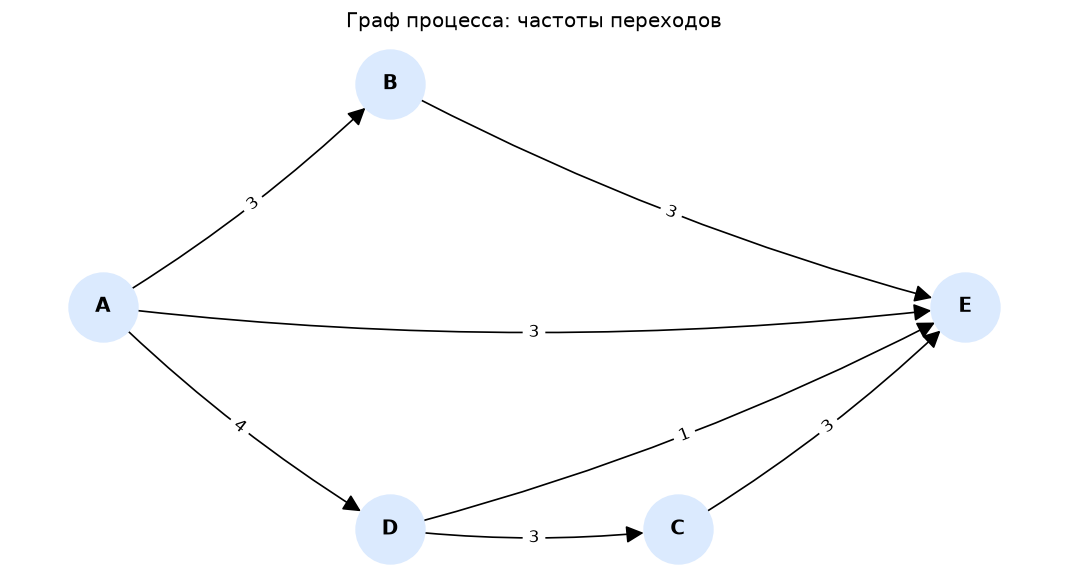

In [5]:
graph = nx.DiGraph()
graph.add_nodes_from(activities)
graph.add_weighted_edges_from((i, j, value) for (i, j), value in selected.items())
assert nx.is_directed_acyclic_graph(graph)
positions = {"A": (0, 0), "B": (1, 1.2), "C": (2, -1.2), "D": (1, -1.2), "E": (3, 0)}
fig, ax = plt.subplots()
nx.draw_networkx_nodes(graph, positions, node_size=1700, node_color="#dbeafe", ax=ax)
nx.draw_networkx_labels(graph, positions, font_size=12, font_weight="bold", ax=ax)
nx.draw_networkx_edges(graph, positions, arrows=True, arrowsize=22, node_size=1700,
                       connectionstyle="arc3,rad=0.06", ax=ax)
nx.draw_networkx_edge_labels(graph, positions, edge_labels=selected, ax=ax,
                             connectionstyle="arc3,rad=0.06")
ax.set_title("Граф процесса: частоты переходов")
ax.axis("off")
plt.tight_layout()
plt.show()

**Проверка на опубликованной матрице длительностей.** Числа ниже взяты с рис. 5 статьи; матрица порядка вычислена по событиям без округления. Эту проверку не следует смешивать с основным расчётом, в котором длительности получены собственной эвристикой.

In [6]:
article_duration = pd.DataFrame(
    [[0, 74, 109, 108, 220], [54, 0, 214, 164, 69],
     [6, 0, 0, 87, 42], [0, 106, 150, 0, 124], [0, 102, 62, 96, 0]],
    index=activities, columns=activities, dtype=float,
)
article_selected, article_objective, article_removed = solve_phase_one(ps, article_duration)
article_edges = pd.DataFrame([
    {"Из": i, "В": j, "Частота": value}
    for (i, j), value in article_selected.items()
])
display(article_edges)
print(f"Значение цели: {article_objective:.8f}")
print("Исключённые циклические дуги:", article_removed if article_removed else "нет")
assert article_selected == {("A", "B"): 3, ("A", "C"): 3, ("A", "D"): 4,
                            ("B", "E"): 3, ("C", "E"): 3, ("D", "E"): 4}

,Из,В,Частота
0,A,B,3
1,A,C,3
2,A,D,4
3,B,E,3
4,C,E,3
5,D,E,4


Значение цели: 748.22273737
Исключённые циклические дуги: нет


**Сопоставление с PM4Py.** Библиотеке передаётся тот же журнал без столбца идентификатора случая. Матрицы сопоставляются по названиям действий. Реализация `classic` самостоятельно вычисляет длительности и строит частотный граф; её ограничения и обработка циклов могут отличаться от модели выше. В используемой версии PM4Py классический алгоритм не задаёт A начальным, а E конечным действием: он балансирует входы и выходы всех типов. Поэтому библиотечный граф может иметь входы в A, выходы из E и циклы. Это различие постановок учитывается при сравнении, а не устраняется изменением результата библиотеки. Документация: [Correlation Miner в PM4Py](https://processintelligence.solutions/pm4py/examples/process-discovery).

In [7]:
log = events.rename(columns={"activity": "concept:name"})[["concept:name", "seconds"]].copy()
log["time:timestamp"] = pd.Timestamp("2020-01-01", tz="UTC") + pd.to_timedelta(log["seconds"], unit="s")
log = log[["concept:name", "time:timestamp"]]
stream, grouped, library_activities = classic.preprocess_log(log)
library_ps_values, library_duration_values = classic.get_PS_dur_matrix(grouped, library_activities)
library_ps = pd.DataFrame(library_ps_values, index=library_activities, columns=library_activities).loc[activities, activities]
library_duration = pd.DataFrame(library_duration_values, index=library_activities, columns=library_activities).loc[activities, activities]

matrix_comparison = pd.DataFrame([
    {"Из": i, "В": j, "P/S свой": ps.loc[i, j], "P/S PM4Py": library_ps.loc[i, j],
     "D свой, с": duration.loc[i, j], "D PM4Py, с": library_duration.loc[i, j]}
    for i, j in itertools.permutations(activities, 2)
])
display(matrix_comparison)
ps_difference = np.max(np.abs(matrix_comparison["P/S свой"] - matrix_comparison["P/S PM4Py"]))
print(f"Максимальное расхождение P/S: {ps_difference:.12f}")
assert np.isclose(ps_difference, 0)

,Из,В,P/S свой,P/S PM4Py,"D свой, с","D PM4Py, с"
0,A,B,0.467,0.467,107.667,51.667
1,A,C,0.967,0.967,296.000,71.333
2,A,D,0.725,0.725,153.500,65.750
3,A,E,0.880,0.880,220.100,220.100
4,B,A,0.533,0.533,51.333,27.333
5,B,C,1.000,1.000,213.667,213.667
6,B,D,0.667,0.667,174.000,153.000
7,B,E,0.900,0.900,27.333,27.333
8,C,A,0.033,0.033,5.000,5.000
9,C,B,0.000,0.000,0.000,0.000


Максимальное расхождение P/S: 0.000000000000


**Контроль с длительностями PM4Py при ограничениях статьи.** Чтобы отдельно оценить влияние матрицы длительностей, подставим рассчитанную библиотекой матрицу в нашу модель с началом A и концом E.

In [8]:
library_duration_selected, library_duration_objective, library_duration_removed = solve_phase_one(ps, library_duration)
display(pd.DataFrame([
    {"Из": i, "В": j, "Частота": value}
    for (i, j), value in library_duration_selected.items()
]))
print(f"Значение цели: {library_duration_objective:.8f}")
print("Исключённые циклические дуги:", library_duration_removed if library_duration_removed else "нет")
assert library_duration_selected == article_selected

,Из,В,Частота
0,A,B,3
1,A,C,3
2,A,D,4
3,B,E,3
4,C,E,3
5,D,E,4


Значение цели: 444.30691050
Исключённые циклические дуги: нет


**Прямой вызов PM4Py classic.** Библиотечный граф вычисляется без подгонки; ограничения о начале и конце процесса к нему не добавляются.

In [9]:
library_frequency, library_performance = correlation_miner.apply(
    log, variant=correlation_miner.Variants.CLASSIC
)
all_edges = sorted(set(selected) | set(library_frequency))
graph_comparison = pd.DataFrame([
    {"Из": i, "В": j, "Своя модель": selected.get((i, j), 0),
     "PM4Py classic": library_frequency.get((i, j), 0)}
    for i, j in all_edges
])
display(graph_comparison)

balance_comparison = pd.DataFrame([
    {"Действие": a, "Событий": counts[a],
     "Вход своя": sum(v for (i, j), v in selected.items() if j == a),
     "Выход своя": sum(v for (i, j), v in selected.items() if i == a),
     "Вход PM4Py": sum(v for (i, j), v in library_frequency.items() if j == a),
     "Выход PM4Py": sum(v for (i, j), v in library_frequency.items() if i == a)}
    for a in activities
])
display(balance_comparison)

,Из,В,Своя модель,PM4Py classic
0,A,B,3,3
1,A,D,4,4
2,A,E,3,3
3,B,E,3,3
4,C,E,3,3
5,D,A,0,3
6,D,C,3,0
7,D,E,1,1
8,E,A,0,7
9,E,C,0,3


,Действие,Событий,Вход своя,Выход своя,Вход PM4Py,Выход PM4Py
0,A,10,0,10,10,10
1,B,3,3,3,3,3
2,C,3,3,3,3,3
3,D,4,4,4,4,4
4,E,10,10,0,10,10


## Ответ

Для мини-журнала собственная эвристика и целочисленная модель дают переходы **A → B: 3, A → D: 4, A → E: 3, B → E: 3, C → E: 3, D → C: 3, D → E: 1**. Значение целевой функции — примерно **845,296666 с**. Полученный граф ацикличен.

При подстановке опубликованной матрицы длительностей получается граф из рис. 2(c): **A → B: 3, A → C: 3, A → D: 4, B → E: 3, C → E: 3, D → E: 4**. Значение цели при точных значениях P/S — примерно **748,222737 с**.

Матрица P/S совпадает с PM4Py для всех пар разных действий. Если использовать длительности PM4Py при ограничениях статьи, получается граф рис. 2(c) со значением цели **444,306911 с**. При прямом вызове PM4Py classic результат отличается: библиотека балансирует также начало и конец, поэтому её граф содержит обратные дуги и циклы. Сравнение частот и балансов приведено выше.